# 01 · The NHS readmissions data

**Question:** what does the official NHS England readmissions file contain, and what can we
honestly model with it?

**Source:** NHS England, *Compendium: Emergency readmissions to hospital within 30 days of
discharge* (indicator I02040), 2025 release, Open Government Licence v3.0. One CSV, 155,573 rows,
financial years 2014/15 to 2024/25.

The indicator: of all discharges from hospital in a year, the percentage followed by an
**emergency** readmission to any English hospital within 30 days.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsread import viz
from nhsread.config import COMPENDIUM_FILE
from nhsread.ingest.contracts import validate_cells, validate_tidy
from nhsread.ingest.reader import deprivation_cells, providers, read_compendium

viz.set_style()
pd.set_option("display.width", 140)
tidy = validate_tidy(read_compendium(COMPENDIUM_FILE))
cells = validate_cells(deprivation_cells(tidy))
print(f"{len(tidy):,} rows, {tidy['year'].nunique()} financial years; data contract passed")

155,573 rows, 11 financial years; data contract passed


## 1. What is in the file?
Each row is one geography or organisation (the *level*) for one year, age band, sex and method.

In [2]:
structure = (tidy.groupby("breakdown", observed=True)
             .agg(levels=("level", "nunique"), rows=("level", "size"))
             .sort_values("rows", ascending=False))
structure

,levels,rows
breakdown,,
Lower tier local authority,336,51725
Provider,451,46880
CCG/sub-ICB,245,26685
Treatment Function,149,16858
STP/ICB,42,5670
Area Classification,24,3960
Region,9,1485
NHS England Region,7,1155
Deprivation quintile,6,990


Two **methods** are published:

* **Snapshot**: all ages, compared with England *in the same year*. `expected` is the number of
  readmissions the unit would have had at England's age/sex-specific rates.
* **Trend**: separate rows for age bands (<16, 16-74, 75+, and 16+), standardised to a fixed
  reference so years can be compared.

The published `value` is an **indirectly standardised rate**: (observed / expected) x the England
rate. We will rebuild this ourselves in notebook 03.

In [3]:
e = tidy[(tidy["breakdown"] == "England") & (tidy["method"] == "Snapshot") & (tidy["sex"] == "Persons")]
e = e.set_index("year")[["num", "den", "value"]]
e["crude_check"] = 100 * e["num"] / e["den"]
e.style.format({"num": "{:,.0f}", "den": "{:,.0f}", "value": "{:.1f}", "crude_check": "{:.2f}"})

,num,den,value,crude_check
year,,,,
2014/15,"722,506","5,735,201",12.6,12.60
2015/16,"747,323","5,757,945",13.0,12.98
2016/17,"762,078","5,823,691",13.1,13.09
2017/18,"806,741","5,931,677",13.6,13.60
2018/19,"883,775","6,242,589",14.2,14.16
2019/20,"908,781","6,365,261",14.3,14.28
2020/21,"762,875","4,941,801",15.4,15.44
2021/22,"863,467","6,015,583",14.4,14.35
2022/23,"837,569","5,901,936",14.2,14.19


## 2. Data quality: suppression and rounding

In [4]:
sub = tidy[tidy["breakdown"] != "England"]
q = pd.Series({
    "rows with suppressed numerator (*)": sub["suppressed"].mean(),
    "rows flagged 'Caution' (small numbers)": sub["caution"].mean(),
    "rows whose numerator is a multiple of 5": (sub["num"].dropna() % 5 == 0).mean(),
})
(100 * q).round(1).astype(str) + "%"

rows with suppressed numerator (*)          11.6%
rows flagged 'Caution' (small numbers)      13.0%
rows whose numerator is a multiple of 5    100.0%
dtype: str

Sub-national counts are **rounded to the nearest 5** (a disclosure control), so every derived rate
carries a little rounding noise. This matters later: it is why our recreation of NHS banding
agrees ~98% rather than 100%.

## 3. The national trend

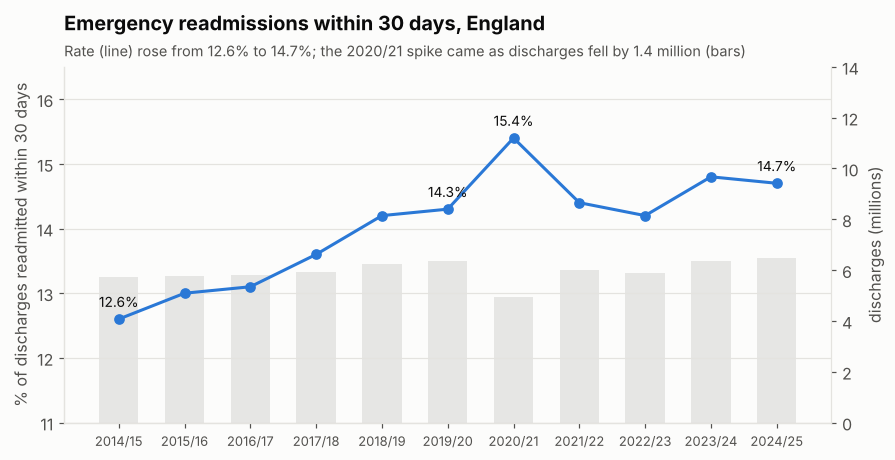

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(e))
ax.plot(x, e["value"], marker="o", color=viz.BLUE)
for i, (yr, r) in enumerate(e["value"].items()):
    if yr in {"2014/15", "2019/20", "2020/21", "2024/25"}:
        ax.annotate(f"{r:.1f}%", (i, r), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xticks(x, e.index, rotation=0, fontsize=8.5)
ax.set_ylabel("% of discharges readmitted within 30 days")
ax.set_ylim(11, 16.5)
ax2 = ax.twinx()
ax2.bar(x, e["den"] / 1e6, color=viz.GREY, alpha=0.25, width=0.6)
ax2.set_ylabel("discharges (millions)", color=viz.TEXT_2)
ax2.set_ylim(0, 14)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.set_title("Emergency readmissions within 30 days, England")
viz.subtitle(ax, "Rate (line) rose from 12.6% to 14.7%; the 2020/21 spike came as discharges fell by 1.4 million (bars)")
viz.save(fig, "01_england_trend")
fig

Two features to carry forward: a **steady upward drift** (12.6% to 14.7% over a decade) and a
**COVID year** (2020/21) in which discharges fell by about 1.4 million while the rate jumped to
15.4%: planned (elective) care largely stopped, so the patients still being discharged were, on average, a higher-risk mix. Any model of the trend
needs to treat 2020/21 as special.

## 4. Who is readmitted? Age, sex and deprivation (2024/25)

In [6]:
latest = cells[cells["year"] == "2024/25"]
by = lambda col: latest.groupby(col)[["num", "den"]].sum().assign(rate=lambda d: 100 * d["num"] / d["den"])
pd.concat({"age band": by("age")["rate"], "sex": by("sex")["rate"], "IMD quintile (1 = most deprived)": by("imd")["rate"]}).round(2).to_frame("rate %")

rate %
age band                         16-74    13.80
                                 75+      17.86
                                 <16      13.09
sex                              Female   14.54
                                 Male     14.94
IMD quintile (1 = most deprived) 1        15.58
                                 2        15.04
                                 3        14.59
                                 4        14.14
                                 5        13.87

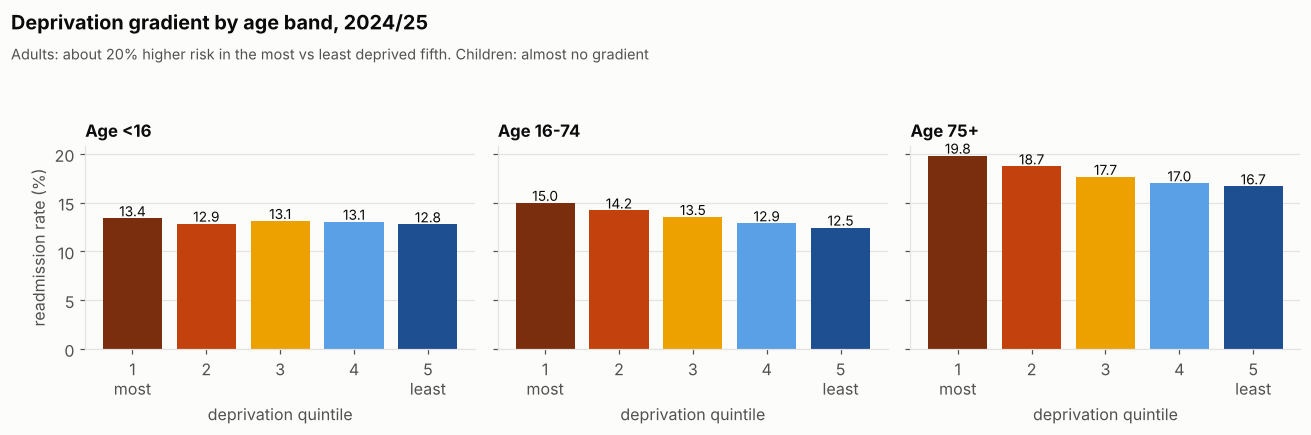

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, a in zip(axes, ["<16", "16-74", "75+"], strict=True):
    s = latest[latest["age"] == a].groupby("imd")[["num", "den"]].sum()
    r = 100 * s["num"] / s["den"]
    ax.bar(r.index, r.values, color=[viz.IMD_COLOURS[i] for i in r.index])
    for i, v in r.items():
        ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
    ax.set_xticks(range(1, 6), ["1\nmost", "2", "3", "4", "5\nleast"])
    ax.set_title(f"Age {a}", fontsize=11, pad=6)
    ax.set_xlabel("deprivation quintile")
axes[0].set_ylabel("readmission rate (%)")
viz.fig_title(fig, "Deprivation gradient by age band, 2024/25",
              "Adults: about 20% higher risk in the most vs least deprived fifth. Children: almost no gradient")
viz.save(fig, "01_deprivation_by_age")
fig

Readmission rises with age (75+ is the highest-risk band) and with deprivation. But the
deprivation gradient is **not the same at every age**: adults in the most deprived fifth of areas
are about 20% more likely to be readmitted than those in the least deprived, while for children
the gradient almost disappears. In model terms, that is an **interaction** (deprivation x age), and a model without it
would mis-state the inequality for most patients.

## 5. Hospital trusts: size and rate

In [8]:
p = providers(tidy, "2024/25")
print(f"{len(p)} NHS trusts with published counts in 2024/25; "
      f"discharges per trust: median {p['den'].median():,.0f}, range {p['den'].min():,.0f} to {p['den'].max():,.0f}")
p["band"].value_counts().reindex(["A1", "A5", "W", "B5", "B1"]).rename("trusts (NHS banding)").to_frame()

154 NHS trusts with published counts in 2024/25; discharges per trust: median 37,935, range 135 to 193,340


,trusts (NHS banding)
band,
A1,43
A5,3
W,25
B5,13
B1,70


NHS England's own banding marks **most trusts as statistically above or below England at the
99.8% level**. That is a warning sign, not a finding: with tens of thousands of discharges per
trust the confidence intervals are tiny, and genuine differences between hospitals (coding,
local services, case mix not captured by age and sex) swamp them. Notebook 03 deals with this
properly with over-dispersion.

## 6. The modelling dataset for Part 1

The rows that line up into a complete, mutually exclusive grid are:
**5 deprivation quintiles x 3 age bands x 2 sexes x 11 years = 330 cells**, each with
readmissions (`num`) out of discharges (`den`). That is exactly the input a **grouped binomial
logistic regression** needs.

In [9]:
print(f"{len(cells)} cells covering {cells['den'].sum():,} discharges and {cells['num'].sum():,} readmissions")
cells.head(6)

330 cells covering 64,665,775 discharges and 9,095,590 readmissions


,year,year_start,imd,age,sex,num,den,rate,logit
0,2014/15,2014,1,16-74,Female,61505,498880,0.123286,-1.961672
1,2014/15,2014,1,16-74,Male,55360,400040,0.138386,-1.828759
2,2014/15,2014,1,75+,Female,28860,151875,0.190025,-1.449850
3,2014/15,2014,1,75+,Male,20705,100775,0.205458,-1.352526
4,2014/15,2014,1,<16,Female,12675,106975,0.118486,-2.006850
5,2014/15,2014,1,<16,Male,15825,133645,0.118411,-2.007567


**Takeaways**

* The file is aggregated, not patient-level, but it is rich: real numerators, denominators and
  expected counts by age, sex, deprivation, year, trust and specialty.
* Readmission rates rose about 2 points in a decade, with a COVID spike in 2020/21.
* Risk rises with age and deprivation, and the deprivation effect depends on age.
* The published trust banding flags most trusts, which points to over-dispersion.